# Single-Stock Risk Report

**Author:** Sterling Couts

## Purpose and conventions

Analyze one stock over a requested date range using the validated `ohlc_hw_cleaned` table.

Use adjusted close for performance and drawdown. Calculate daily log returns for volatility, Sharpe ratio, and daily-return statistics. Annualization assumes 252 trading days; Sharpe uses the assignment’s approximation with a 2% annual risk-free rate.

Keep numeric results as fractions and apply percentage formatting only for display. Report actual observed coverage, which may be shorter than the requested period.

## 1. Report parameters

The following cell supplies the values that Papermill will override during automated execution. Its notebook metadata must include the `parameters` tag.

In [1]:
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
from pathlib import Path
from contextlib import closing
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

database = Path(db_path).resolve()

if not database.is_file():
    raise FileNotFoundError(f"Working database not found: {database}")

if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError("Ticker must be a nonempty string.")

ticker = ticker.strip().upper()
requested_start = pd.Timestamp(start_date)
requested_end = pd.Timestamp(end_date)

if (
    pd.isna(requested_start)
    or pd.isna(requested_end)
    or requested_start > requested_end
):
    raise ValueError("Provide valid dates with start_date <= end_date.")

with closing(sqlite3.connect(
    database.as_uri() + "?mode=ro", uri=True
)) as conn:
    prices = pd.read_sql_query(
        """
        SELECT ts, ticker, adj_close
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
        """,
        conn,
        params=(
            ticker,
            requested_start.strftime("%Y-%m-%d"),
            requested_end.strftime("%Y-%m-%d"),
        ),
        parse_dates=["ts"],
    )

if len(prices) < 21:
    raise ValueError(
        f"{ticker}: found {len(prices)} prices; "
        "at least 21 are required for 20 daily returns."
    )

if prices["ts"].duplicated().any():
    raise ValueError("Duplicate observation dates.")

if not (
    np.isfinite(prices["adj_close"])
    & prices["adj_close"].gt(0)
).all():
    raise ValueError("Adjusted prices must be finite and strictly positive.")

prices = prices.set_index("ts")

print(
    f"{ticker} from {requested_start:%Y-%m-%d} "
    f"to {requested_end:%Y-%m-%d}: {len(prices)} trading days"
)
print(
    f"Actual coverage: {prices.index.min():%Y-%m-%d} "
    f"to {prices.index.max():%Y-%m-%d}"
)

display(prices.head())
display(prices.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual coverage: 2024-01-02 to 2024-10-18


,ticker,adj_close
ts,,
2024-01-02,AAPL,184.94
2024-01-03,AAPL,183.55
2024-01-04,AAPL,181.22
2024-01-05,AAPL,180.50
2024-01-08,AAPL,184.86


,ticker,adj_close
ts,,
2024-10-14,AAPL,231.30
2024-10-15,AAPL,233.85
2024-10-16,AAPL,231.78
2024-10-17,AAPL,232.15
2024-10-18,AAPL,235.00


## 2. Risk calculations

Calculate daily log returns from adjusted close. Estimate 20-return rolling volatility using the sample standard deviation, annualized by multiplying by √252. Preserve unavailable warm-up estimates.

Calculate per-date drawdown relative to the running adjusted-price peak. The worst drawdown is the minimum of this series.

Use the assignment’s Sharpe approximation:

`(252 × mean daily log return − 0.02) / (√252 × sample standard deviation)`

Return an undefined Sharpe value when fewer than two returns are available or volatility is zero. Annualized estimates describe the observed sample; they are not forecasts.

In [3]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns; preserve the missing first return."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(
    returns: pd.Series, window: int = 20
) -> pd.Series:
    """Calculate annualized rolling sample volatility over full windows."""
    if window < 2:
        raise ValueError("Volatility window must be at least 2.")
    return returns.rolling(window, min_periods=window).std(
        ddof=1
    ) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown, not its minimum or cumulative minimum."""
    return prices / prices.cummax() - 1


def calculate_sharpe_ratio(
    returns: pd.Series, risk_free_rate: float = 0.02
) -> float:
    """Calculate the course's annualized Sharpe approximation."""
    observed = returns.dropna()

    if len(observed) < 2:
        return np.nan

    sigma = observed.std(ddof=1)
    # Treat roundoff-scale variation in constant returns as zero volatility.
    zero_tolerance = np.finfo(float).eps * max(1.0, abs(observed.mean()))
    if not np.isfinite(sigma) or sigma <= zero_tolerance:
        return np.nan

    return (
        observed.mean() * 252 - risk_free_rate
    ) / (sigma * np.sqrt(252))

In [4]:
test_prices = pd.Series([100.0, 120.0, 90.0, 108.0])
test_returns = calculate_returns(test_prices)
test_drawdown = calculate_max_drawdown(test_prices)

assert pd.isna(test_returns.iloc[0])
np.testing.assert_allclose(
    test_returns.iloc[1:],
    np.log([1.20, 0.75, 1.20]),
)

np.testing.assert_allclose(
    test_drawdown,
    [0.0, 0.0, -0.25, -0.10],
    atol=1e-12,
)
assert np.isclose(test_drawdown.min(), -0.25)

# Two returns: sample variance = (0.01² + 0.01²) / (2 - 1).
two_returns = pd.Series([0.01, -0.01])
expected_sigma = np.sqrt(0.0002)
expected_annual_vol = expected_sigma * np.sqrt(252)

test_volatility = calculate_volatility(two_returns, window=2)
assert pd.isna(test_volatility.iloc[0])
assert np.isclose(test_volatility.iloc[1], expected_annual_vol)

assert np.isclose(
    calculate_sharpe_ratio(two_returns),
    -0.02 / expected_annual_vol,
)
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.0, 0.0])))
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01])))

print("Return, volatility, drawdown, and Sharpe checks passed.")
# Nonzero constant returns can leave a tiny floating-point sample std.
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01] * 10)))
assert pd.isna(calculate_sharpe_ratio(pd.Series([-0.01] * 10)))
print("Nonzero constant-return Sharpe regression checks passed.")


Return, volatility, drawdown, and Sharpe checks passed.
Nonzero constant-return Sharpe regression checks passed.


**Metric verification:** Controlled checks passed for log-return ratios, drawdown and recovery, sample-volatility annualization, and the course Sharpe formula. Zero-volatility and insufficient-return examples produced undefined Sharpe values.

In [5]:
prices["log_return"] = calculate_returns(prices["adj_close"])
prices["volatility_20"] = calculate_volatility(prices["log_return"])
prices["drawdown"] = calculate_max_drawdown(prices["adj_close"])
prices["ma_50"] = prices["adj_close"].rolling(
    50, min_periods=50
).mean()

assert prices["volatility_20"].iloc[:20].isna().all()
assert pd.notna(prices["volatility_20"].iloc[20])
assert prices["ma_50"].iloc[:49].isna().all()

if len(prices) >= 50:
    assert pd.notna(prices["ma_50"].iloc[49])
else:
    print("50-day moving average unavailable: fewer than 50 prices.")

print("Defined daily returns:", prices["log_return"].notna().sum())
print("Sharpe ratio:", calculate_sharpe_ratio(prices["log_return"]))
print("Maximum drawdown:", f'{prices["drawdown"].min():.2%}')
print("Rolling warm-up checks passed.")

Defined daily returns: 201
Sharpe ratio: 1.187256558320051
Maximum drawdown: -15.35%
Rolling warm-up checks passed.


## 3. Summary statistics

Total return uses the first and last observed adjusted closes. Compounded annualized return uses the mean daily log return and 252 trading days per year. Whole-period volatility uses the sample standard deviation of all available daily log returns; it differs from mean rolling volatility.

Best/worst days and conditional up/down averages use log returns. The proportion of positive days includes zero returns in its denominator but excludes undefined returns. Empty conditional subsets display as N/A.

All metrics describe actual observed coverage within the requested window.

In [6]:
observed_returns = prices["log_return"].dropna()
up_returns = observed_returns.loc[observed_returns.gt(0)]
down_returns = observed_returns.loc[observed_returns.lt(0)]

summary_metrics = pd.Series({
    "Total Return": (
        prices["adj_close"].iloc[-1] / prices["adj_close"].iloc[0] - 1
    ),
    "Annualized Return": np.expm1(observed_returns.mean() * 252),
    "Annualized Volatility": observed_returns.std(ddof=1) * np.sqrt(252),
    "Sharpe Ratio": calculate_sharpe_ratio(observed_returns),
    "Maximum Drawdown": prices["drawdown"].min(),
    "Best Day": observed_returns.max(),
    "Worst Day": observed_returns.min(),
    "Positive Days": observed_returns.gt(0).mean(),
    "Average Up Day": up_returns.mean(),
    "Average Down Day": down_returns.mean(),
}, name="value")

summary_display = pd.DataFrame({
    "Metric": summary_metrics.index,
    "Value": [
        "N/A" if pd.isna(value)
        else f"{value:.4f}" if metric == "Sharpe Ratio"
        else f"{value:.2%}"
        for metric, value in summary_metrics.items()
    ],
})

# Independent identity: compounded log returns equal endpoint performance.
assert np.isclose(
    np.expm1(observed_returns.sum()),
    summary_metrics["Total Return"],
)

# Zero days belong in the positive-day denominator.
example_daily_returns = pd.Series([0.01, 0.0, -0.02, np.nan]).dropna()
assert np.isclose(example_daily_returns.gt(0).mean(), 1 / 3)

print("Summary identity and denominator checks passed.")

Summary identity and denominator checks passed.


## 4. Risk visualization

Show adjusted prices and a 50-observation moving average, daily log returns, annualized 20-return rolling volatility, and per-date drawdown.

Price segments are red when the ending observation’s rolling volatility exceeds the report’s mean rolling volatility, green otherwise, and gray when volatility is unavailable. This coloring is retrospective.

Preserve warm-up gaps. Mark the worst drawdown while displaying the full drawdown path, including recoveries. Include actual coverage alongside the requested reporting period.

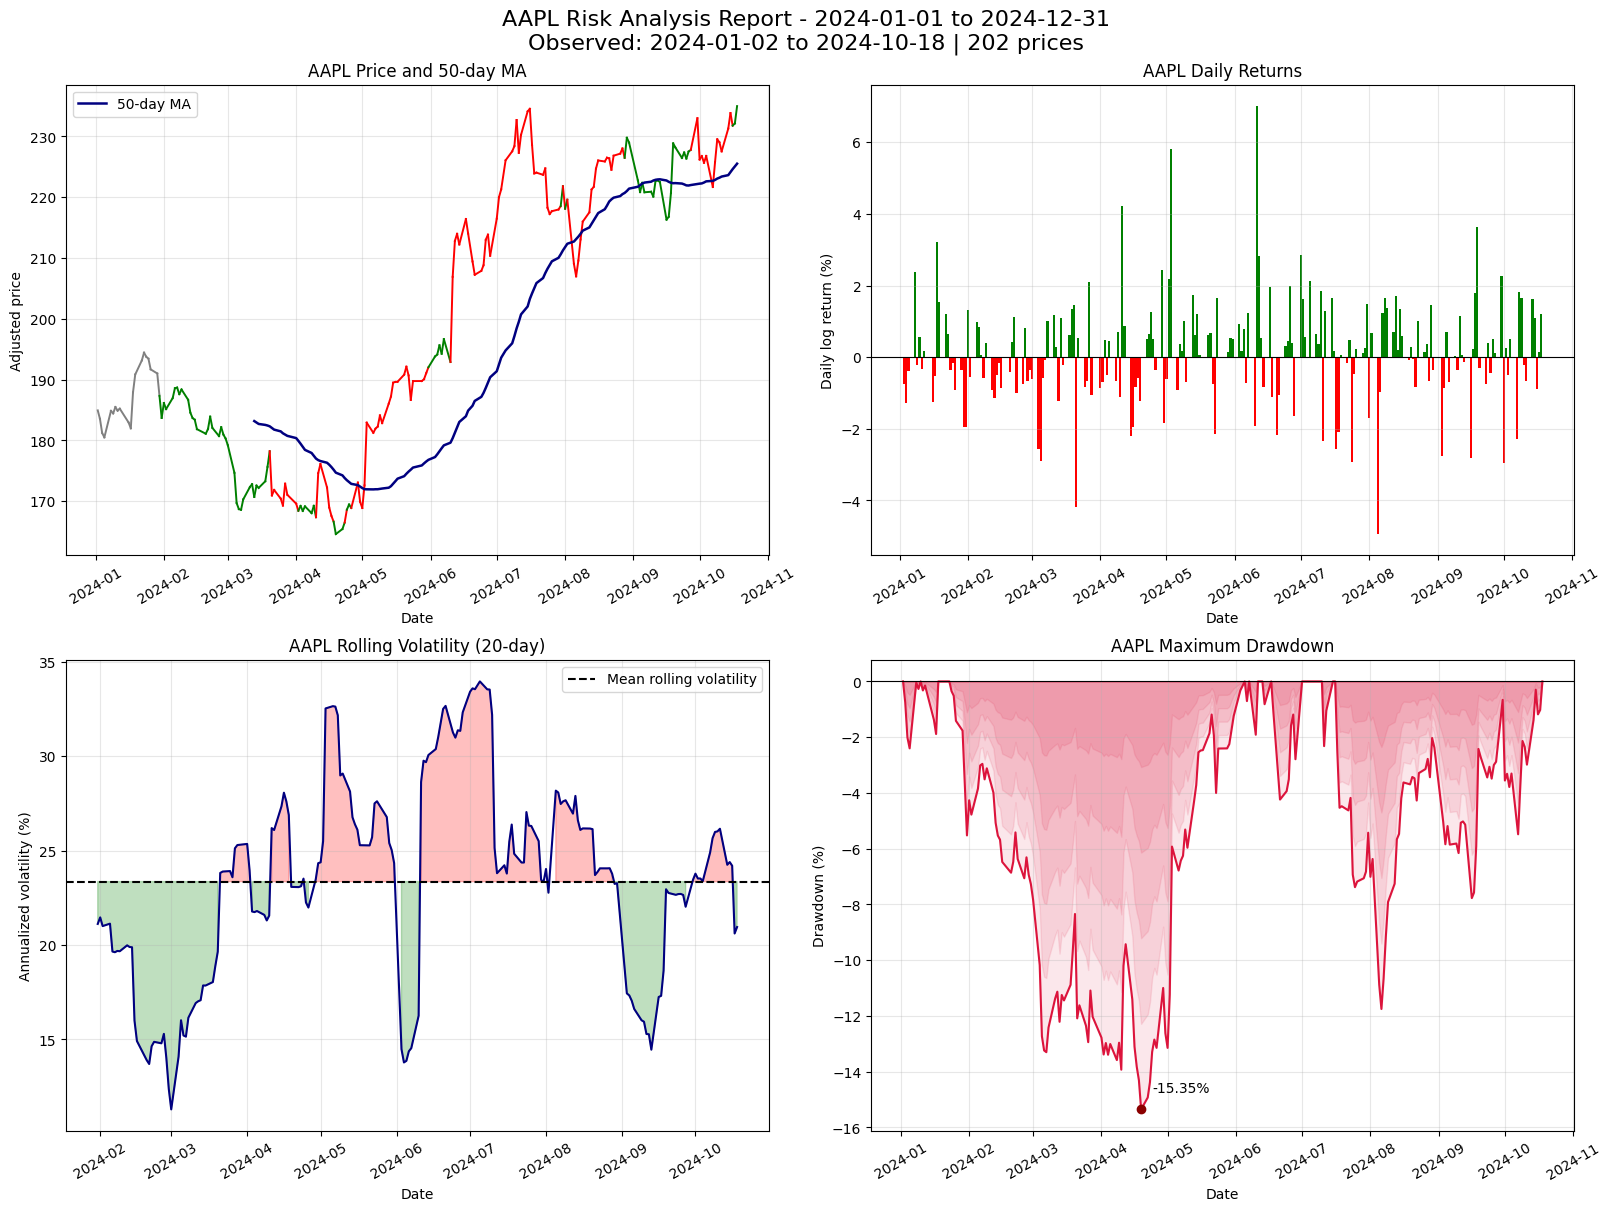

In [7]:
fig, axes = plt.subplots(
    2, 2, figsize=(16, 12), layout="constrained"
)
price_ax, returns_ax, vol_ax, drawdown_ax = axes.ravel()

mean_rolling_vol = prices["volatility_20"].mean()

# Color each segment using its ending observation's volatility.
for position in range(1, len(prices)):
    volatility = prices["volatility_20"].iloc[position]

    color = (
        "gray" if pd.isna(volatility)
        else "red" if volatility > mean_rolling_vol
        else "green"
    )

    price_ax.plot(
        prices.index[position - 1:position + 1],
        prices["adj_close"].iloc[position - 1:position + 1],
        color=color,
        linewidth=1.4,
    )

price_ax.plot(
    prices.index, prices["ma_50"],
    color="navy", linewidth=1.8, label="50-day MA",
)
price_ax.set(
    title=f"{ticker} Price and 50-day MA",
    xlabel="Date",
    ylabel="Adjusted price",
)
price_ax.legend()

if len(prices) < 50:
    price_ax.text(
        0.02, 0.95, "50-day MA unavailable: fewer than 50 prices",
        transform=price_ax.transAxes, va="top",
    )

bar_colors = np.where(
    observed_returns.gt(0), "green",
    np.where(observed_returns.lt(0), "red", "gray"),
)
returns_ax.bar(
    observed_returns.index,
    observed_returns * 100,
    color=bar_colors,
    width=1.0,
)
returns_ax.axhline(0, color="black", linewidth=0.8)
returns_ax.set(
    title=f"{ticker} Daily Returns",
    xlabel="Date",
    ylabel="Daily log return (%)",
)

vol_pct = prices["volatility_20"] * 100
mean_vol_pct = mean_rolling_vol * 100

vol_ax.plot(prices.index, vol_pct, color="navy")
vol_ax.axhline(
    mean_vol_pct, color="black", linestyle="--",
    label="Mean rolling volatility",
)
vol_ax.fill_between(
    prices.index, vol_pct, mean_vol_pct,
    where=vol_pct.gt(mean_vol_pct),
    color="red", alpha=0.25,
)
vol_ax.fill_between(
    prices.index, vol_pct, mean_vol_pct,
    where=vol_pct.lt(mean_vol_pct),
    color="green", alpha=0.25,
)
vol_ax.set(
    title=f"{ticker} Rolling Volatility (20-day)",
    xlabel="Date",
    ylabel="Annualized volatility (%)",
)
vol_ax.legend()

drawdown_pct = prices["drawdown"] * 100
drawdown_ax.plot(prices.index, drawdown_pct, color="crimson")

# Overlapping transparent fills create the requested red/pink gradient.
for fraction in np.linspace(0.2, 1.0, 5):
    drawdown_ax.fill_between(
        prices.index, drawdown_pct * fraction, 0,
        color="crimson", alpha=0.10,
    )

worst_date = prices["drawdown"].idxmin()
worst_drawdown = drawdown_pct.loc[worst_date]

drawdown_ax.scatter(
    [worst_date], [worst_drawdown], color="darkred", zorder=5,
)
drawdown_ax.annotate(
    f"{worst_drawdown:.2f}%",
    xy=(worst_date, worst_drawdown),
    xytext=(8, 12), textcoords="offset points",
)
drawdown_ax.axhline(0, color="black", linewidth=0.8)
drawdown_ax.set(
    title=f"{ticker} Maximum Drawdown",
    xlabel="Date",
    ylabel="Drawdown (%)",
)

for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    f"{ticker} Risk Analysis Report - {start_date} to {end_date}\n"
    f"Observed: {prices.index.min():%Y-%m-%d} to "
    f"{prices.index.max():%Y-%m-%d} | {len(prices)} prices",
    fontsize=16,
)

plt.show()

## 5. Export results for automated collection

Store named numeric metrics inside the executed notebook using Scrapbook. Keep returns, volatility, and drawdown as fractions rather than formatted percentage strings.

Include actual observation dates and counts so comparisons can disclose unequal coverage. The batch summary will collect outputs only from reports that completed successfully.

**Export verification:** During template development, the saved Scrapbook fields were read back and checked against the calculated metrics. All required fields were present and the tested values matched. VS Code may display renderer notices for these machine-readable outputs.

In [8]:
import scrapbook as sb

report_metrics = {
    "ticker": ticker,
    "start_date": requested_start.strftime("%Y-%m-%d"),
    "end_date": requested_end.strftime("%Y-%m-%d"),
    "actual_start": prices.index.min().strftime("%Y-%m-%d"),
    "actual_end": prices.index.max().strftime("%Y-%m-%d"),
    "trading_days": int(len(prices)),
    "avg_daily_return": float(observed_returns.mean()),
    "avg_volatility": float(prices["volatility_20"].mean()),
    "max_drawdown": float(summary_metrics["Maximum Drawdown"]),
    "sharpe_ratio": float(summary_metrics["Sharpe Ratio"]),
    "total_return": float(summary_metrics["Total Return"]),
}

for name, value in report_metrics.items():
    # Use None for an undefined numeric metric so it exports as JSON null.
    exported_value = (
        None
        if isinstance(value, float) and not np.isfinite(value)
        else value
    )
    sb.glue(name, exported_value)

print("Named report metrics exported.")

Named report metrics exported.


## 6. Final summary

Daily best/worst and up/down averages are log returns. Total and annualized returns are compounded simple returns. The values below describe the actual observed coverage reported above, not an extrapolation through missing trailing dates.


In [9]:
display(summary_display)

,Metric,Value
0,Total Return,27.07%
1,Annualized Return,35.03%
2,Annualized Volatility,23.61%
3,Sharpe Ratio,1.1873
4,Maximum Drawdown,-15.35%
5,Best Day,7.01%
6,Worst Day,-4.94%
7,Positive Days,55.72%
8,Average Up Day,1.08%
9,Average Down Day,-1.09%
